# GOES X-ray plots and flare-class annotations

## 1. The original real-time plot from NOAA

This X-Ray plot was created on 21 July 2025.
It shows GOES-19 as primary and GOES-18 as secondary. 

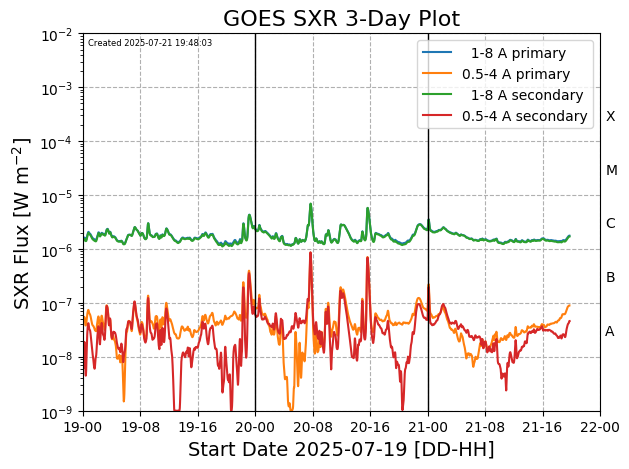

This plot will be our reference plot, and we will build a similar plot in stages using pyspedas. 
The reference plot is using real-time data; for our plot we will use science-quality, calibrated data. 


## 2. Load the one-minute X-ray data

Load GOES-19 and GOES-18 from the same interval. The data stop sat the reference
image's creation time. Use `datatype="1min"` and `level="l2"` to select NCEI's science-quality
one-minute product.

| Channel | Wavelength band | Variables |
|---|---|---|
| XRS-B | 1–8 Å | `g19_xrs_xrsb_flux`, `g18_xrs_xrsb_flux` |
| XRS-A | 0.5–4 Å | `g19_xrs_xrsa_flux`, `g18_xrs_xrsa_flux` |

Flare classes describe the **XRS-B (1–8 Å)** flux. The same class labels should
not be used to classify the XRS-A (0.5–4 Å) measurements.

In [ ]:
from datetime import datetime
from pyspedas import annotate, get_data, options, store_data, time_clip, timebar, tplot, tplot_options, del_data
from pyspedas.projects import goes

del_data('*')
start = "2025-07-19"
end = "2025-07-22"
cutoff = "2025-07-21 19:48:03"

loaded = goes.xrs(
    probe=["19", "18"],
    trange=[start, end],
    datatype="1min",
    level="l2",
    time_clip=False,
)

# This order will also determine the colors and legend entries later.
flux_vars = [
    "g19_xrs_xrsb_flux",
    "g19_xrs_xrsa_flux",
    "g18_xrs_xrsb_flux",
    "g18_xrs_xrsa_flux",
]
missing = [name for name in flux_vars if get_data(name) is None]
if missing:
    raise RuntimeError(f"Required variables were not loaded: {missing}")

# Clip the selected flux variables explicitly to the reference interval.
time_clip(flux_vars, start, cutoff, overwrite=True)

print("Loaded the four X-ray flux variables.")

Loaded the four X-ray flux variables.


## 3. A simple plot using tplot

`tplot_options()` sets global figure options, while `options()` controls a single panel.
The code below applies the global settings before creating the first plot.

Function `store_data()` creates a new variable that combines the four existing variables into one overlaid panel. 
These are ordinary tplot options: a logarithmic flux axis,
shared limits, a basic palette, and a legend. No flare-class annotations or
boundary lines are added here.

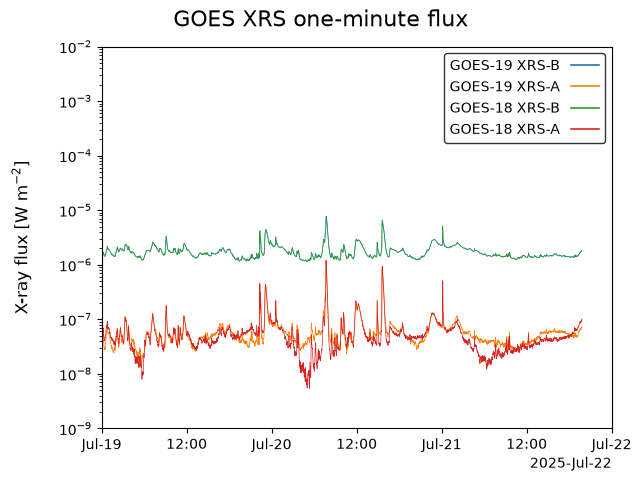

In [16]:
# Global options control the figure; options() below controls a single panel.
tplot_options("title", "GOES XRS one-minute flux")
tplot_options("title_size", 16)

# Use the same flux limits throughout the examples.
yrange = [1e-9, 1e-2]

simple_panel = "goes_xrs_simple"
store_data(simple_panel, data=flux_vars)
options(
    simple_panel,
    opt_dict={
        "ylog": True,
        "yrange": yrange,
        "ytitle": r"X-ray flux [W m$^{-2}$]",
        "color": ["C0", "C1", "C2", "C3"],
        "legend_names": ["GOES-19 XRS-B", "GOES-19 XRS-A", "GOES-18 XRS-B", "GOES-18 XRS-A"],
        "legend_size": 10,
        "legend_linewidth": 1.2,
        "grid": False,
    },
)
tplot(simple_panel, trange=[start, end], xsize=6.3, ysize=4.7, display=True)

## 4. Add the GOES flare-class scale

Apply the helper `add_goes_xray_annotations()` once to the combined panel, then call `tplot()` again.
The underlying flux values, trace colors, and legend remain the same.

The helper adds dashed horizontal boundaries and **A/B/C/M/X** labels at the
right edge, centered within each logarithmic decade. It also enables log
scaling and applies `yrange` when supplied. We already set the same scale and
range above so the new decorations are easy to compare.

| Class | Lower boundary in W/m² |
|---|---|
| A | 10⁻⁸ |
| B | 10⁻⁷ |
| C | 10⁻⁶ |
| M | 10⁻⁵ |
| X | 10⁻⁴ |

The boundary at 10⁻³ W/m² represents **X10**, not an upper limit on X-class
flares. Labels outside the visible range are hidden. Repeating the helper
replaces its own earlier decorations while preserving other annotations and bars.
See [NOAA's solar-flare classification](https://www.swpc.noaa.gov/phenomena/solar-flares-radio-blackouts).

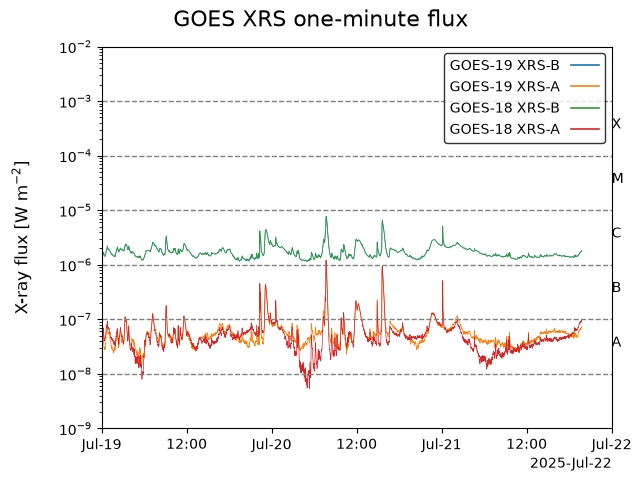

In [17]:
goes.add_goes_xray_annotations(simple_panel, yrange=yrange, fontsize=10)
tplot(simple_panel, trange=[start, end], xsize=6.3, ysize=4.7, display=True)

## 5. Approximate the reference styling with automatic time ticks

Now use a fresh combined panel and match the reference's colors, legend,
title, flux-axis label, and line widths. In this example, **blue/orange** are
GOES-19 and **green/red** are GOES-18. The solid blue and green XRS-B traces
nearly overlap, so one may obscure the other.

The helper supplies the horizontal boundaries. An x-only grid supplies vertical
dashed lines at the automatically chosen major time ticks—normally **12 UTC**
between the midnight ticks for this figure size and interval. Solid black
`timebar()` lines emphasize **00 UTC**. Tick spacing is automatic at this stage.

The `Created` text below deliberately uses the reference image's timestamp;
it is not the time this notebook is run. All customization in this section
uses PySPEDAS functions.

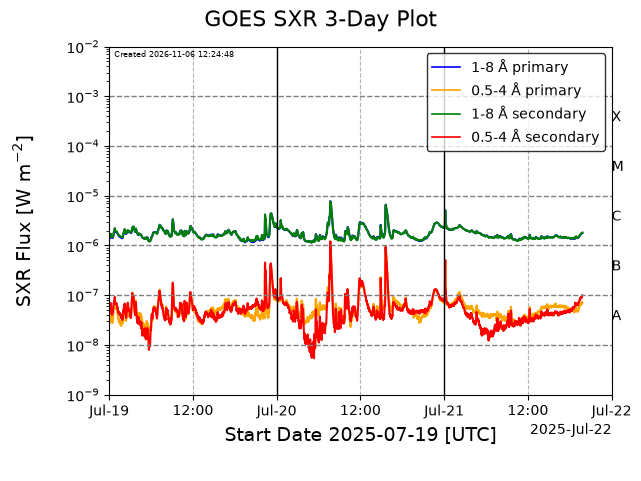

In [19]:
styled_panel = "goes_xrs_reference_style"
store_data(styled_panel, data=flux_vars)

# Combined panels obtain their x-axis labels from the component variables.
options(flux_vars, opt_dict={"xtitle": f"Start Date {start} [UTC]", "xsubtitle": ""})
tplot_options("title", "GOES SXR 3-Day Plot")

options(
    styled_panel,
    opt_dict={
        "color": ["blue", "orange", "green", "red"],
        "legend_names": [
            "1-8 Å primary",
            "0.5-4 Å primary",
            "1-8 Å secondary",
            "0.5-4 Å secondary",
        ],
        "legend_location": "upper right",
        "legend_size": 10,
        "legend_markerfirst": True,
        "legend_linewidth": 1.2,
        "line_width": [1.5, 1.5, 1.5, 1.5],
        "line_style": ["solid", "solid", "solid", "solid"],
        "ytitle": r"SXR Flux [W m$^{-2}$]",
        "ysubtitle": "",
        "char_size": 14,
        "grid": True,
        "grid_properties": {
            "axis": "x",
            "which": "major",
            "linestyle": "--",
            "color": "0.7",
            "linewidth": 0.8,
        },
    },
)
goes.add_goes_xray_annotations(styled_panel, yrange=yrange, fontsize=10)

# Midnight lines are solid; the grid supplies the intermediate dashed lines.
midnight_times = ["2025-07-20", "2025-07-21"]
timebar(midnight_times, varname=styled_panel, color="black", thick=1)
created = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
annotate(styled_panel, f"Created {created}", position=(0.01, 0.97), fontsize="6")
tplot(styled_panel, trange=[start, end], xsize=6.3, ysize=4.7, display=True)

## 6. Move the intermediate vertical bars to 08 and 16 UTC

Turn off the automatic grid and draw dashed gray `timebar()` lines explicitly
at **08 and 16 UTC** each day. The solid midnight lines and the helper's
horizontal boundaries remain in place.

**Bars and ticks are separate.** Adding bars does not move the time-axis
labels. This version of PySPEDAS has no option to specify x-axis tick positions,
so the labels may still show **12:00** even though the bars now have eight-hour
spacing. The next section adjusts the returned Matplotlib axis directly.

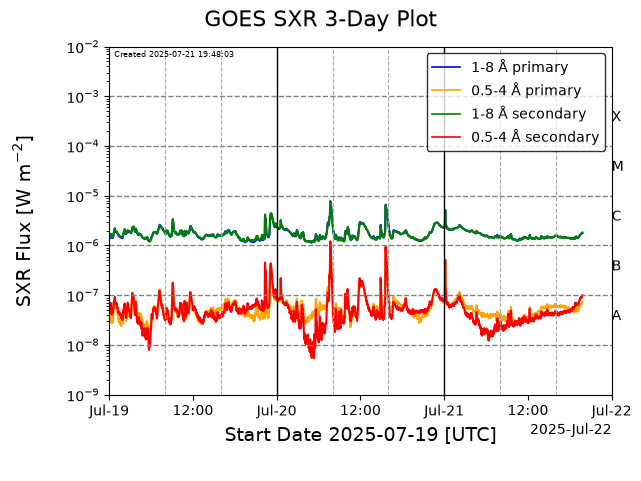

In [5]:
options(styled_panel, "grid", False)
eight_hour_times = [
    f"{day} {hour}:00:00"
    for day in ("2025-07-19", "2025-07-20", "2025-07-21")
    for hour in ("08", "16")
]

# Remove matching bars first so rerunning this cell does not duplicate them.
timebar(eight_hour_times, varname=styled_panel, delete=True)
timebar(eight_hour_times, varname=styled_panel, color="darkgray", thick=0.8, dash=True)
tplot(styled_panel, trange=[start, end], xsize=6.3, ysize=4.7, display=True)

## 7. Match the tick positions and labels with Matplotlib

Ask `tplot()` to return its figure and axes without displaying them yet.
An [HourLocator](https://matplotlib.org/stable/api/dates_api.html#matplotlib.dates.HourLocator)
places ticks at **00, 08, and 16 UTC**, and a
[DateFormatter](https://matplotlib.org/stable/api/dates_api.html#matplotlib.dates.DateFormatter)
displays them as **DD-HH**, matching labels such as `19-08` in the reference.
The timezone is explicitly UTC.

This is the only section that directly customizes a Matplotlib axis. The
change applies to this returned figure; it does not add a new PySPEDAS option
or persist in the tplot variable. Calling `tplot()` again would restore its
automatic tick selection unless these Matplotlib adjustments are repeated.

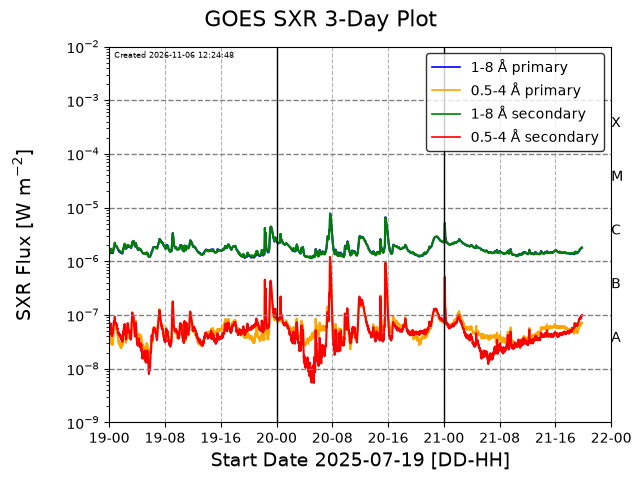

In [20]:
from datetime import timezone

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import display

fig, axes = tplot(
    styled_panel,
    trange=[start, end],
    xsize=6.3,
    ysize=4.7,
    display=False,
    return_plot_objects=True,
)
ax = fig.axes[0]  # This example has one panel.
ax.xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 8, 16], tz=timezone.utc))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%H", tz=timezone.utc))
ax.set_xlabel(f"Start Date {start} [DD-HH]", fontsize=14)

# Display after changing the ticks; close to avoid a duplicate inline figure.
display(fig)
plt.close(fig)

## 8. Why might the orange and red lines differ from the 2025 image?

The reference
is a real-time operational plot; this notebook loads NCEI's reprocessed
science-quality product. NOAA documents retrospective calibration and algorithm
changes, including time-dependent dark-count treatment. Its release history lists:

- **15 December 2025, v2-2-1:** revised responsivities and electron-contamination calibrations.
- **6 October 2026, v2-2-2:** updated electron-contamination coefficients for one-minute averages.

See the [NOAA XRS L2 Readme, sections 3–5](https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/goes16/l2/docs/GOES-R_XRS_L2_Data_ReadMe.pdf).

Orange and red represent **XRS-A (0.5–4 Å)**. The plotted `xrsa_flux` variables
include electron-contamination correction. That correction can have a much
larger relative effect on the weak XRS-A signal than on the stronger XRS-B
signal in this interval. This is a plausible explanation for similar blue/green
curves but different orange/red curves. NOAA describes the correction and its
limitations in the [XRS L2 User's Guide, section 4](https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/goes16/l2/docs/GOES-R_XRS_L2_Data_Users_Guide.pdf).

Future runs may use newer files. Calibration and processing differences may give different results.



## 9. The full script, using pyspedas commands only

This self-contained script reproduces **stage 5**. It includes all imports,
data loading, global settings, panel styling, flare-class annotations, and
solid midnight lines. The automatic x-axis grid supplies the dashed lines
at 12 UTC for this figure size and time range. It does not add the 08/16 UTC
bars or customize Matplotlib ticks.



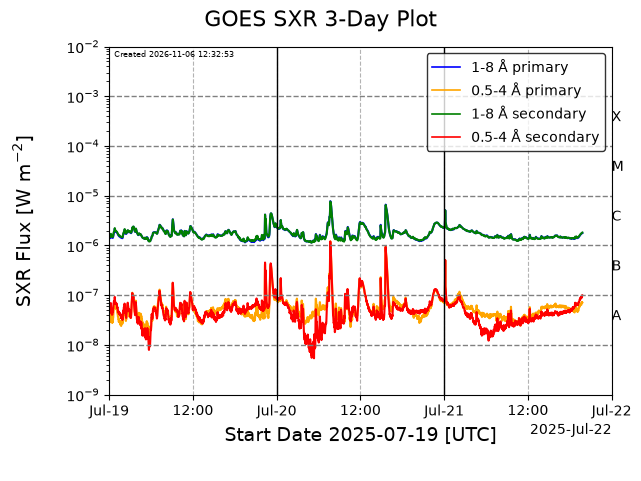

In [21]:
from datetime import datetime
from pyspedas import annotate, get_data, options, store_data, time_clip, timebar, tplot, tplot_options, del_data
from pyspedas.projects import goes


# Match the reference interval and data cutoff.
start = "2025-07-19"
end = "2025-07-22"
cutoff = "2025-07-21 19:48:03"
yrange = [1e-9, 1e-2]

# Load the one-minute science-quality X-ray data for both satellites.
del_data('*')
loaded = goes.xrs(
    probe=["19", "18"],
    trange=[start, cutoff],
    datatype="1min",
    level="l2",
    time_clip=False,
)
flux_vars = [
    "g19_xrs_xrsb_flux",
    "g19_xrs_xrsa_flux",
    "g18_xrs_xrsb_flux",
    "g18_xrs_xrsa_flux",
]
missing = [name for name in flux_vars if get_data(name) is None]
if missing:
    raise RuntimeError(f"Required variables were not loaded: {missing}")
time_clip(flux_vars, start, cutoff, overwrite=True)

# Set all global options used by stage 5, without relying on earlier cells.
tplot_options("title", "GOES SXR 3-Day Plot")
tplot_options("title_size", 16)
tplot_options("axis_font_size", 10)
tplot_options("background", "white")
tplot_options("foreground", "black")
tplot_options("grid", False)

# Recreate the combined panel so earlier plots cannot leave extra bars on it.
panel = "goes_xrs_stage5_complete"
store_data(panel, data=flux_vars)
options(flux_vars, opt_dict={"xtitle": f"Start Date {start} [UTC]", "xsubtitle": ""})

# Colors and legend entries follow the order in flux_vars.
# The solid blue and green XRS-B traces nearly overlap.
options(
    panel,
    opt_dict={
        "color": ["blue", "orange", "green", "red"],
        "legend_names": [
            "1-8 Å primary",
            "0.5-4 Å primary",
            "1-8 Å secondary",
            "0.5-4 Å secondary",
        ],
        "legend_location": "upper right",
        "legend_size": 10,
        "legend_markerfirst": True,
        "legend_linewidth": 1.2,
        "line_width": [1.5, 1.5, 1.5, 1.5],
        "line_style": ["solid", "solid", "solid", "solid"],
        "ytitle": r"SXR Flux [W m$^{-2}$]",
        "ysubtitle": "",
        "char_size": 14,
        "grid": True,
        "grid_properties": {
            "axis": "x",  # The helper supplies the horizontal boundaries.
            "which": "major",
            "linestyle": "--",
            "color": "0.7",
            "linewidth": 0.8,
        },
    },
)

# Add the flare-class scale for the XRS-B (1–8 Å) flux.
goes.add_goes_xray_annotations(panel, yrange=yrange, fontsize=10)

# Solid lines emphasize midnight; the automatic grid marks 12 UTC.
timebar(["2025-07-20", "2025-07-21"], varname=panel, color="black", thick=1)
created = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
annotate(panel, f"Created {created}", position=(0.01, 0.97), fontsize="6")

# Keep automatic time ticks, as in stage 5. No Matplotlib calls are needed.
tplot(panel, trange=[start, end], xsize=6.3, ysize=4.7, display=True)
